# 1. Clustering of writing systems via siamese neural networks

In this notebook we perform a clustering of writing systems using the siamese-based distance.

- Authors: Claire Roman, Philippe Meyer
- Email: philippemeyer68@yahoo.fr
- Date: 06/2024

In [1]:
# packages
import copy
import math
import networkx as nx
import numpy as np
import os
import pandas as pd
import pickle
import plotly.express as px
import plotly.io as io
import seaborn as sns
from IPython.display import display
from matplotlib import pyplot as plt
from networkx.drawing.nx_pydot import graphviz_layout
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster, leaves_list
from sklearn.manifold import MDS

In [2]:
# CHANGE TO YOUR DIRECTORY PATH
path_directory = "C:/Users/meyerp/Documents/Glyph/worldwide/code github/glyph-worldwide/"

In [3]:
os.chdir(path_directory)

from src.clustering_quality_indices import Davies_Bouldin, Dunn
import src.distance_functions as distance_functions
from src.phylogenetic_tree import phylogenetic_tree
import src.radialtree_modified as rt

model_name = "siamese"
model_name = "1350k"

# Computation of the siamese-based distance between writing systems

- We load the alphabets.

In [4]:
alphabets = os.listdir("data/processed/alphabets/")
alphabets.remove("X_Phaistos Disc.npy")
alphabets.remove("X_Elbasan.npy")
#alphabets.remove("X_Ahom.npy")
alphabets.remove("X_Toto.npy")
alphabets.remove("X_Tangsa.npy")

alphabets = sorted(alphabets)

print("Number of alphabets:", len(alphabets))
alphabets_short = copy.deepcopy(alphabets)
for i in range(len(alphabets)):
    alphabets_short[i] = alphabets[i][2:-4]

alphabets_short[alphabets_short.index("Ge_ez")] = "Ge`ez"
print("Alphabets", alphabets_short)

Number of alphabets: 123
Alphabets ['Ahom', 'Anatolian Hieroglyphs', 'Arabic', 'Armenian', 'Avestan', 'Balinese', 'Batak', 'Bengali', 'Bhaiksuki', 'Brahmi', 'Buginese', 'Buhid', 'CJK', 'Carian', 'Caucasian Albanian', 'Chakma', 'Cham', 'Chorasmian', 'Coptic', 'Cuneiform', 'Cypriot Syllabary', 'Cypro-Minoan', 'Cyrillic', 'Devanagari', 'Dogra', 'Egyptian Hieroglyphs', 'Elder Futhark', 'Elymaic', 'Ge`ez', 'Georgian Asomtavruli', 'Georgian Mkhedruli', 'Glagolitic', 'Gothic', 'Grantha', 'Greek', 'Gujarati', 'Gunjala Gondi', 'Gurmukhi', 'Hangul Jamo', 'Hanunoo', 'Hatran Aramaic', 'Hebrew', 'Hiragana', 'Imperial Aramaic', 'Javanese', 'Kaithi', 'Kanbun', 'Kannada', 'Katakana', 'Kawi', 'Kharoshthi', 'Khmer', 'Khojki', 'Khudawadi', 'Lao', 'Latin', 'Lepcha', 'Limbu', 'Linear A', 'Linear B', 'Lycian', 'Lydian', 'Mahajani', 'Makasar', 'Malayalam', 'Mandaic', 'Manichaean', 'Marchen', 'Meetei Mayek', 'Meroitic Cursive', 'Meroitic Hieroglyphs', 'Modi', 'Mongolian', 'Multani', 'Myanmar', 'Nabataean', 'N

- We import the siamese-based distance.

In [5]:
similarity_between_languages = distance_functions.similarity_between_languages

- We create the dictionary of distances between the languages.

In [6]:
dict_dist = {}
for i in range(len(alphabets) - 1):
    for j in range(i + 1, len(alphabets)):
        alphabet_1 = alphabets[i]
        alphabet_2 = alphabets[j]
        #print(alphabet_1, alphabet_2)
        X_glyph_1 = np.load("data/processed/alphabets/" + alphabet_1)
        X_glyph_2 = np.load("data/processed/alphabets/" + alphabet_2)
        dictonary_alphabets = (
            "dict_dist_X_"
            + alphabet_1[2:-4]
            + "_"
            + alphabet_2[2:-4]
            + "_"
            + model_name
            + ".dat"
        )
        dict_dist_loc = pickle.load(
            open(
                "data/processed/distances/between_alphabets_without_boustro/" + dictonary_alphabets,
                "rb",
            )
        )
        #print("dict load", len(dict_dist_loc))

        sim = similarity_between_languages(X_glyph_1, X_glyph_2, dict_dist_loc)
        dict_dist[(i, j)] = sim

# Closest and furthest pairs of scripts

- Here are the closest pairs of scripts with respect to the siamese-based distance.

In [7]:
dict_dist_sorted = sorted(dict_dist.items(), key=lambda item: item[1], reverse=False)
for i in range(5):
    print(
        alphabets_short[dict_dist_sorted[i][0][0]],
        alphabets_short[dict_dist_sorted[i][0][1]],
        dict_dist_sorted[i][1],
    )

Old Uyghur Thaana 0.022542410688093532
Anatolian Hieroglyphs Egyptian Hieroglyphs 0.027889193308089866
Old Sogdian Yezidi 0.03513546666455647
Old Uyghur Yezidi 0.0443656359400068
Nabataean Yezidi 0.051930756315291385


- Here are the furthest pairs of scripts with respect to the siamese-based distance.

In [8]:
dict_dist_sorted = sorted(dict_dist.items(), key=lambda item: item[1], reverse=True)
for i in range(5):
    print(
        alphabets_short[dict_dist_sorted[i][0][0]],
        alphabets_short[dict_dist_sorted[i][0][1]],
        dict_dist_sorted[i][1],
    )

Old Uyghur Tangut 0.9989366696132472
Imperial Aramaic Tangut 0.9985879802832982
Kanbun Tangut 0.998464033615335
Coptic Tangut 0.99801494017481
Ge`ez Tangut 0.9980097563838479


- Here are the most isolated scripts in the database of writing systems.

In [9]:
def distance_to_others_languages(i):
    """Computes the distance of a script to all the other scripts."""
    temp = 0
    for j in range(len(alphabets)):
        if j != i:
            temp = temp + dict_dist[(tuple(sorted((i, j))))]
    return temp


dict_dist_others = {}
for i in range(len(alphabets)):
    dict_dist_others[i] = distance_to_others_languages(i)
dict_dist_others = dict(
    sorted(dict_dist_others.items(), key=lambda item: item[1], reverse=True)
)

for i in list(dict_dist_others)[:5]:
    print(alphabets_short[i], dict_dist_others[i])

Tangut 112.48861962455405
Kanbun 100.74804929281629
CJK 97.63846031607802
Javanese 96.04043979865438
Grantha 93.19600633028108


# Hierarchical clustering of writing systems

## Ward-linkage hierarchical clustering of writing systems

We perform a Ward-linkage hierarchical clustering of the writing systems together with the siamese-based distance.

In [10]:
sorted_keys, distances = zip(*sorted(dict_dist.items()))
Z = linkage(distances, method="ward")

## Dendrogram
We plot the dendrogram associated to the clustering.

In [11]:
k = 7  #nb clusters

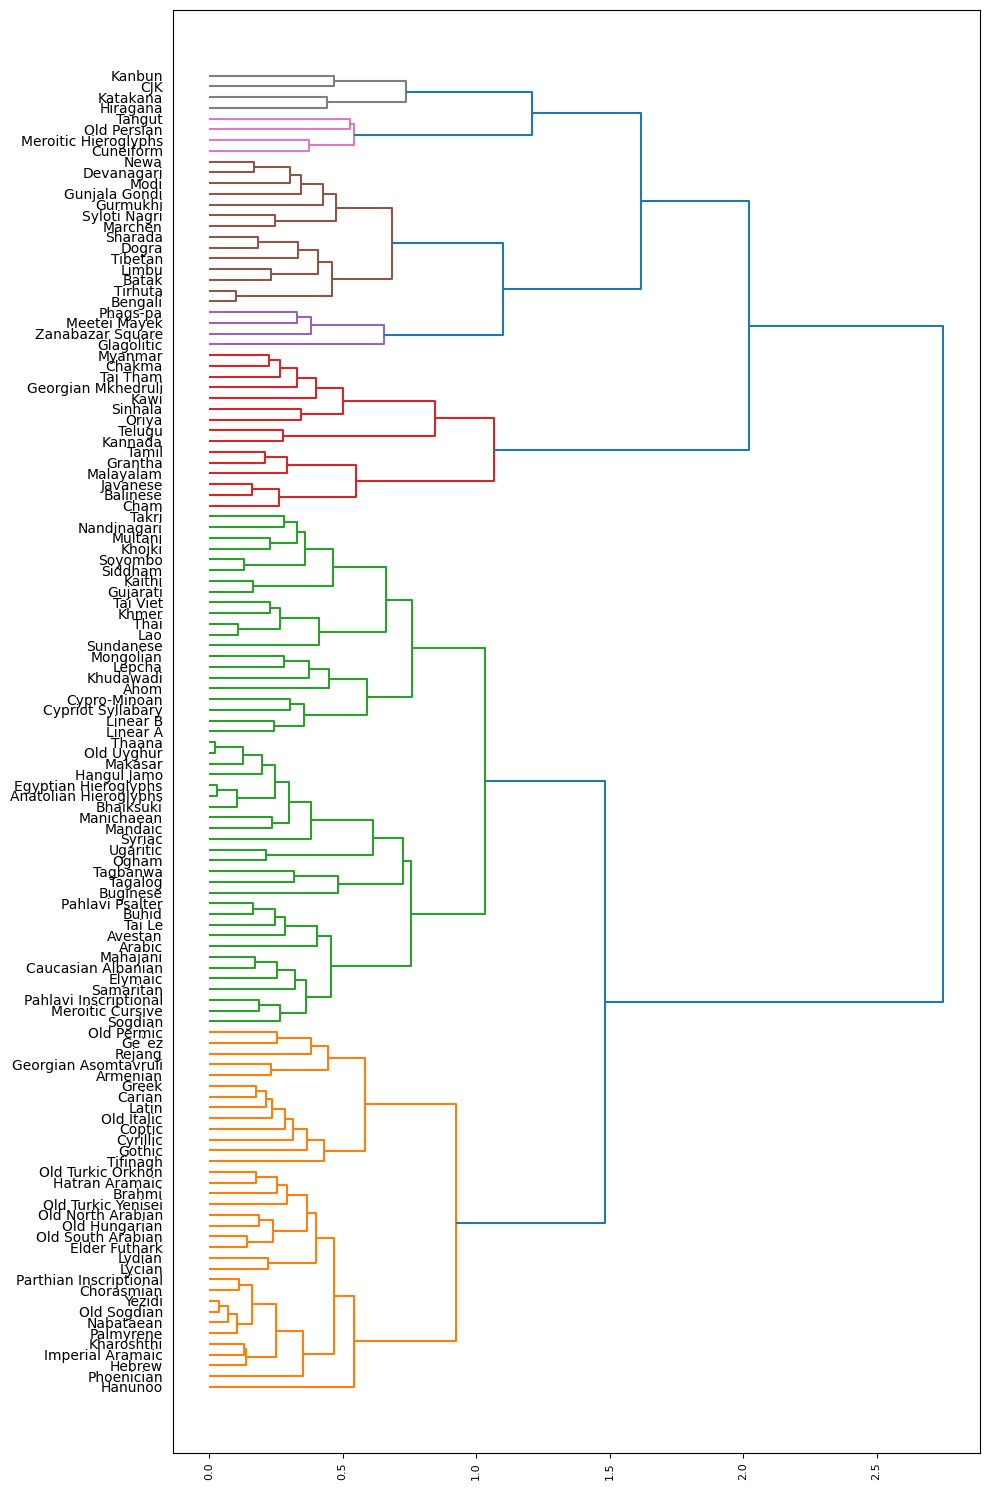

In [12]:
plt.rcParams["figure.figsize"] = [10, 15]
plt.rcParams["figure.autolayout"] = True
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)

color_threshold = Z[-(k-1),2]

dend = dendrogram(
    Z,
    ax=ax,
    truncate_mode="lastp",
    p=len(alphabets),
    show_contracted=True,
    labels=alphabets_short,
    color_threshold=color_threshold,
    orientation="right",
)

ax = plt.gca()
ax.tick_params(axis="y", which="major", labelsize=10)
ax.tick_params(axis="x", which="major", labelsize=8)
plt.xticks(rotation=90)
plt.autoscale()

# to save
plt.rcParams["savefig.dpi"] = 300
# plt.savefig('dendrogram_'+str(k)+'.png', dpi=300, bbox_inches='tight')

plt.show()

- circular

C:\Users\meyerp\Documents\Glyph\worldwide\code github\glyph-worldwide\src\radialtree_modified.py:453: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


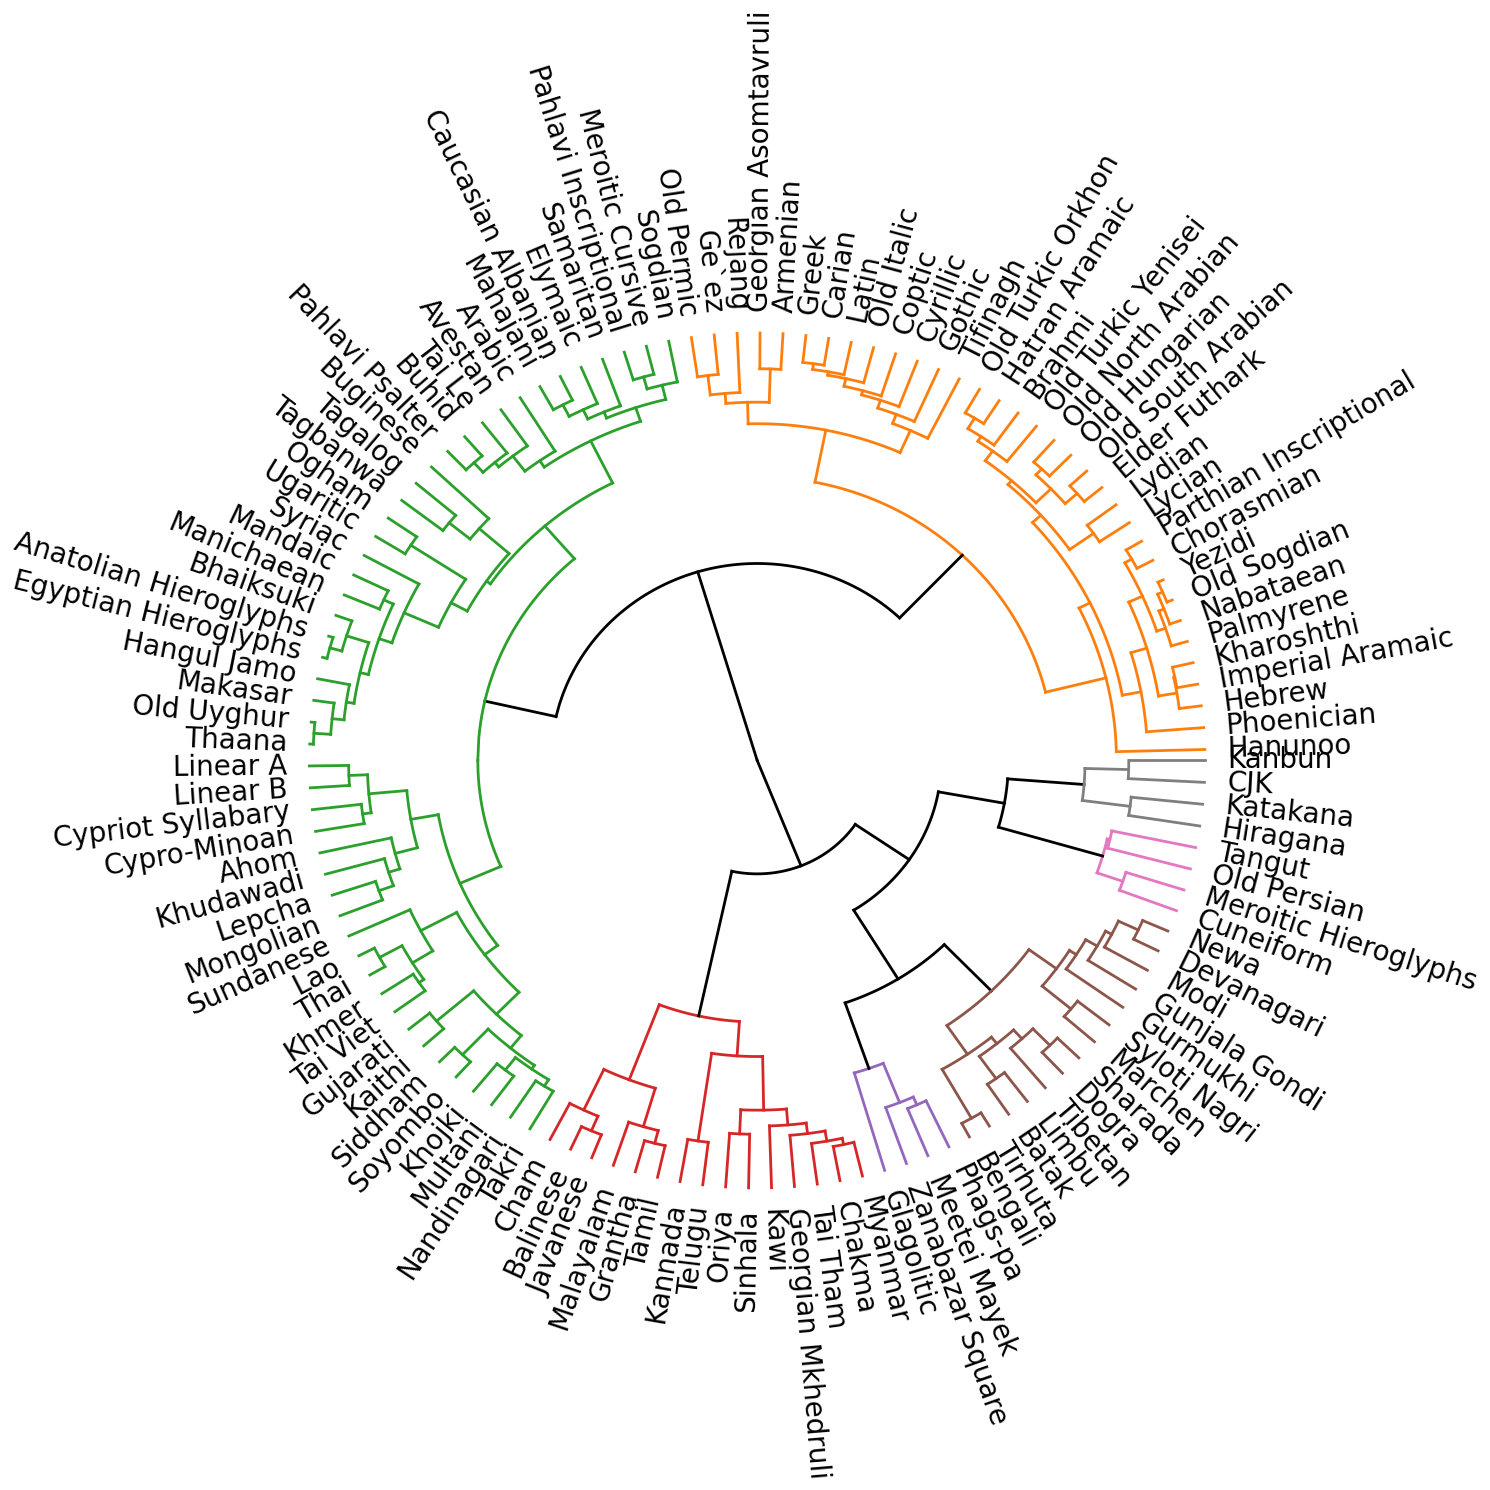

In [13]:
rt.plot(dend, fontsize=20, show=True)

## Elbow method
We compute and plot the explained variation of the clustering.

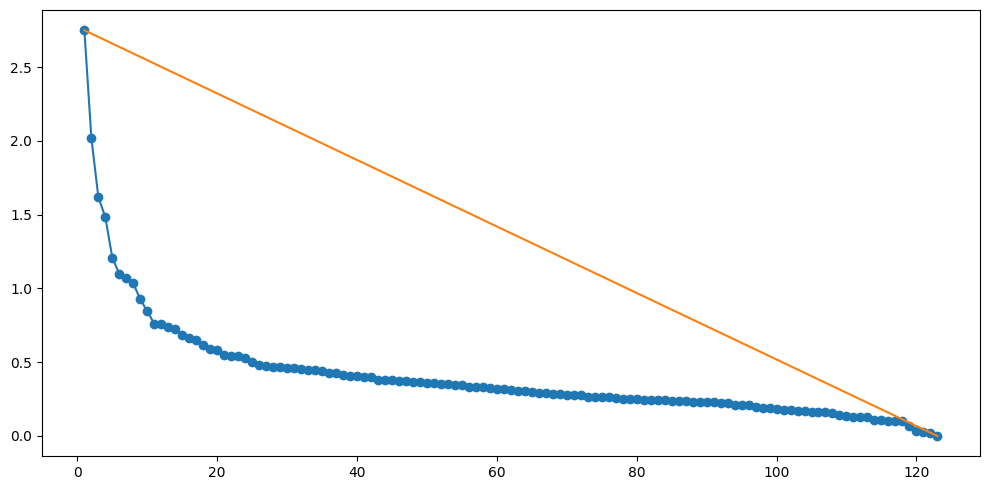

In [14]:
nb_alphabets = len(alphabets)

inertia = list(Z[::-1, 2])[: nb_alphabets - 1]
inertia.append(0)

plt.rcParams["figure.figsize"] = [10, 5]
plt.rcParams["figure.autolayout"] = True
fig, axes = plt.subplots(1, 1)
plt.scatter(range(1, nb_alphabets + 1), inertia)
axes.plot(range(1, nb_alphabets + 1), inertia)
axes.plot([1, nb_alphabets], [inertia[0], inertia[nb_alphabets - 1]])
plt.show()

We define functions to compute the elbow point of curves defined by explained variations.

In [15]:
def find_distance(p1, p2, p3):
    """Computes the distance of the point p3 to the line defined by the points p1 and p2."""
    nom = abs((p2[0] - p1[0]) * (p1[1] - p3[1]) - (p1[0] - p3[0]) * (p2[1] - p1[1]))
    denom = math.sqrt((p2[0] - p1[0]) ** 2 + (p2[1] - p1[1]) ** 2)
    return nom / denom


def elbow_point(inert):
    """Computes the elbow point of an explained variation list."""
    p1 = (1, inert[0])
    p2 = (len(inert), inert[len(inert) - 1])
    maxval = 0
    maxindice = 1
    for i in range(1, len(inert) + 1):
        p3 = (i, inert[i - 1])
        if find_distance(p1, p2, p3) > maxval:
            maxval = find_distance(p1, p2, p3)
            maxindice = i
    return maxindice

We compute all the elbow points by following the explained variation list through the evolution of the clustering.

In [16]:
max_list = []
for temp in range(2, nb_alphabets + 1):
    max_list.append(elbow_point(inertia[:temp]))

(unique, counts) = np.unique(max_list, return_counts=True)
max_dict = {x: y for x, y in zip(unique, counts)}
max_dict = dict(sorted(max_dict.items(), key=lambda item: item[1], reverse=True))

print("The elbow points through the evolution of the clustering:", max_list)
print(
    "The counting of the occurences of the elbow points through the evolution of the clustering:",
    max_dict,
)

The elbow points through the evolution of the clustering: [1, 2, 2, 3, 3, 3, 3, 3, 3, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11]
The counting of the occurences of the elbow points through the evolution of the clustering: {11: 88, 6: 14, 5: 11, 3: 6, 2: 2, 1: 1}


## Clustering
As shown above, the Elbow method clearly indicates to truncate the dendrogram at 10 clusters. 

In [17]:
nb_clus = 15

clusters = fcluster(Z, nb_clus, criterion="maxclust")
clusters = clusters.tolist()
dict_clusters = {}
for i in range(1, nb_clus + 1):
    dict_clusters[i] = []
for i in range(len(clusters)):
    dict_clusters[clusters[i]].append(i)

list_clusters = [0] * len(alphabets)
for i in dict_clusters:
    for j in dict_clusters[i]:
        list_clusters[j] = "C" + str(i)

isolated_scripts = []
for i in dict_clusters:
    if len([alphabets_short[j] for j in dict_clusters[i]]) == 1:
        isolated_scripts.append([alphabets_short[j] for j in dict_clusters[i]][0])
    else:
        print(
            "cluster",
            i,
            [alphabets_short[j] for j in dict_clusters[i]],
            len([alphabets_short[j] for j in dict_clusters[i]]),
        )
print("Isolated scripts:", isolated_scripts)

cluster 1 ['Brahmi', 'Chorasmian', 'Elder Futhark', 'Hanunoo', 'Hatran Aramaic', 'Hebrew', 'Imperial Aramaic', 'Kharoshthi', 'Lycian', 'Lydian', 'Nabataean', 'Old Hungarian', 'Old North Arabian', 'Old Sogdian', 'Old South Arabian', 'Old Turkic Orkhon', 'Old Turkic Yenisei', 'Palmyrene', 'Parthian Inscriptional', 'Phoenician', 'Yezidi'] 21
cluster 2 ['Armenian', 'Carian', 'Coptic', 'Cyrillic', 'Ge`ez', 'Georgian Asomtavruli', 'Gothic', 'Greek', 'Latin', 'Old Italic', 'Old Permic', 'Rejang', 'Tifinagh'] 13
cluster 3 ['Arabic', 'Avestan', 'Buhid', 'Caucasian Albanian', 'Elymaic', 'Mahajani', 'Meroitic Cursive', 'Pahlavi Inscriptional', 'Pahlavi Psalter', 'Samaritan', 'Sogdian', 'Tai Le'] 12
cluster 4 ['Buginese', 'Tagalog', 'Tagbanwa'] 3
cluster 5 ['Anatolian Hieroglyphs', 'Bhaiksuki', 'Egyptian Hieroglyphs', 'Hangul Jamo', 'Makasar', 'Mandaic', 'Manichaean', 'Ogham', 'Old Uyghur', 'Syriac', 'Thaana', 'Ugaritic'] 12
cluster 6 ['Ahom', 'Cypriot Syllabary', 'Cypro-Minoan', 'Khudawadi', 'Lep

In [18]:
list_script = []
list_cluster = []

for i in range(len(alphabets_short)):
    script = alphabets_short[i]
    for cluster in dict_clusters:
        if i in dict_clusters[cluster]:
            script_cluster = cluster
    #print(script, script_cluster)
    list_script.append(script)
    list_cluster.append(script_cluster)
    
df_script_cluster = pd.DataFrame(
    {
        "Script": list_script,
        "Cluster": list_cluster,
    }
)

# df_script_cluster.to_excel("scripts_clusters.xlsx", index=False)

# Phylogenetic tree

In [19]:
df_info = pd.read_excel("C:/Users/meyerp/Documents/Glyph/worldwide/scripts information/scripts_information.xlsx")

C:\Users\meyerp\AppData\Local\Temp\ipykernel_3932\3271037874.py:15: DeprecationWarning: nx.nx_pydot.graphviz_layout depends on the pydot package, which hasknown issues and is not actively maintained. Consider usingnx.nx_agraph.graphviz_layout instead.

See https://github.com/networkx/networkx/issues/5723
  pos = graphviz_layout(G, prog="dot")


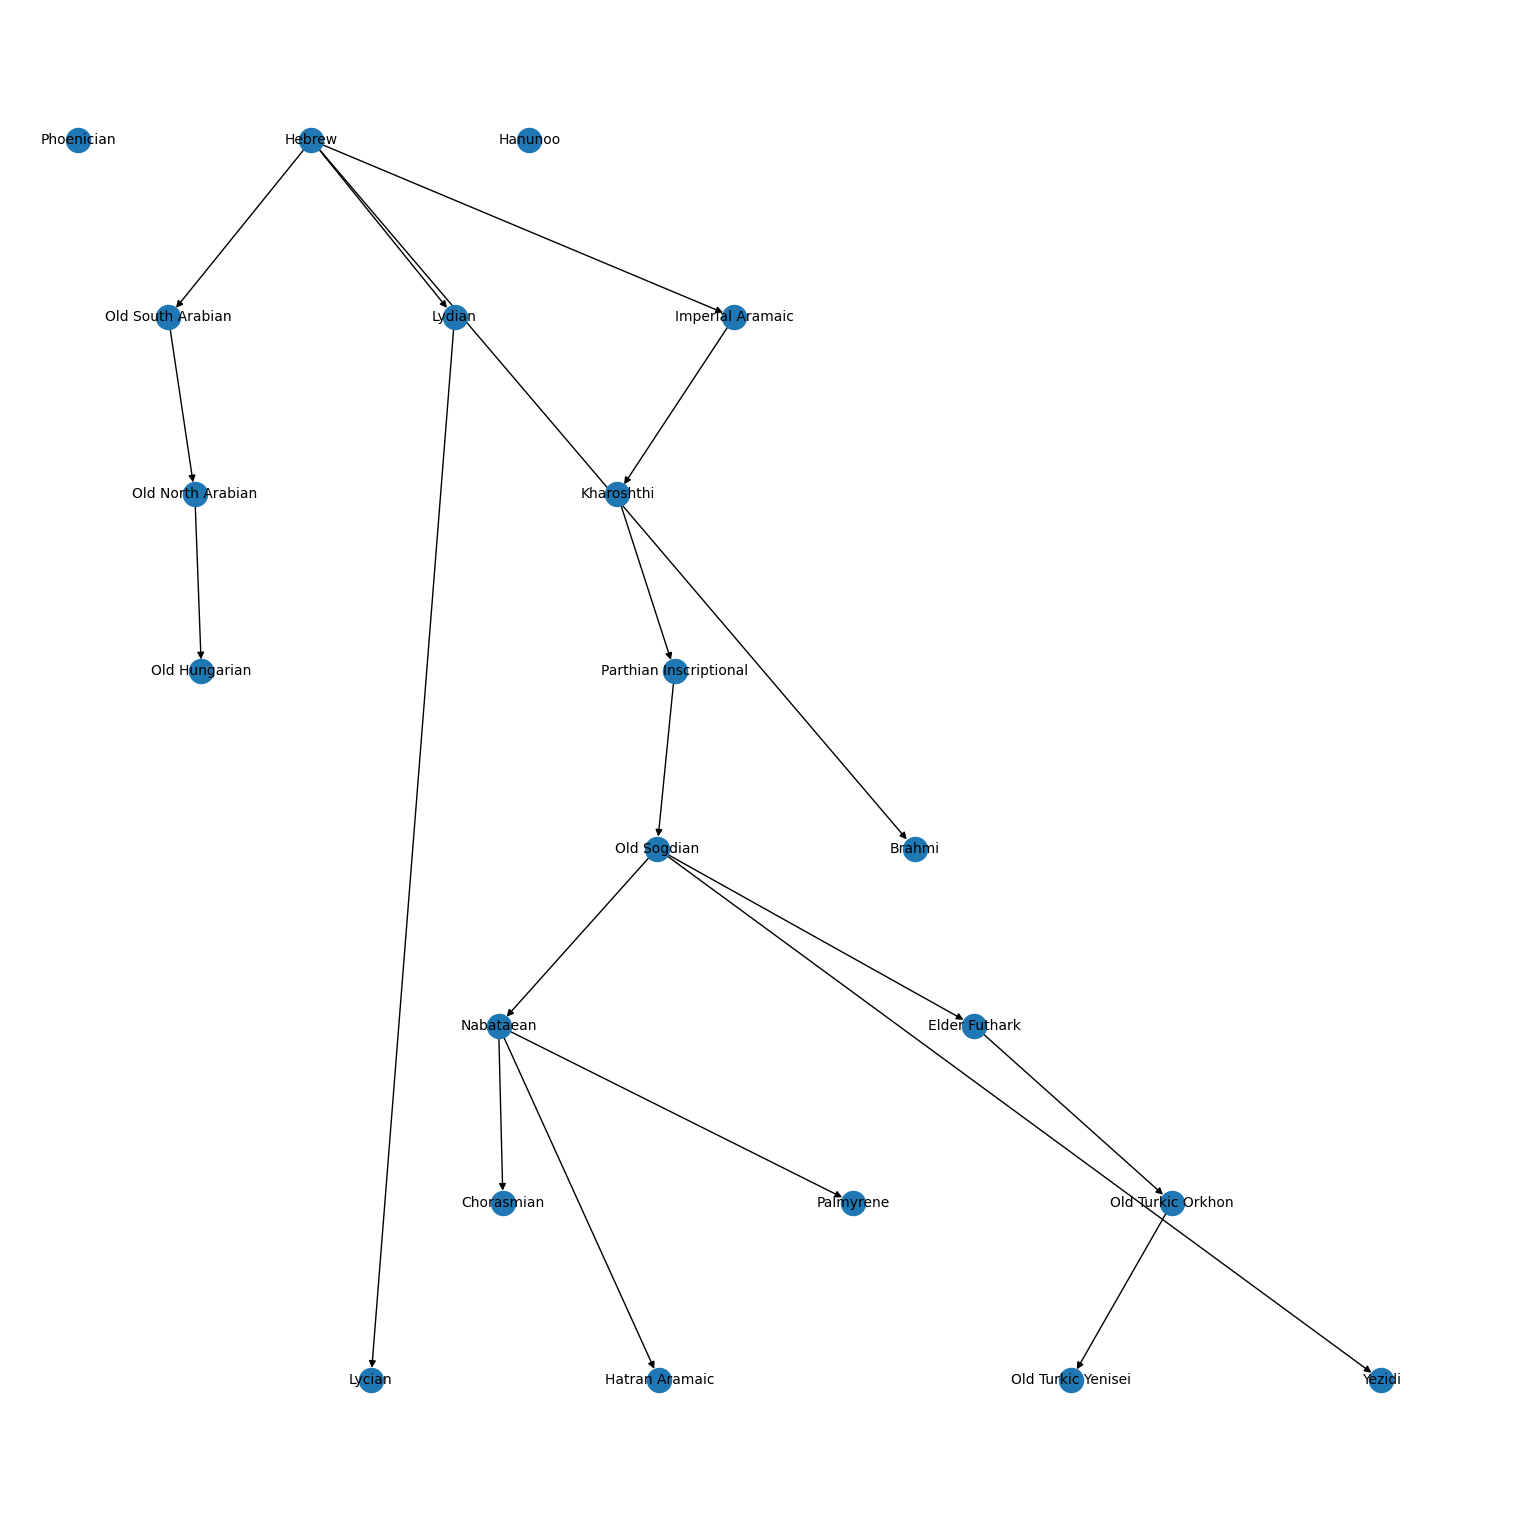

In [22]:
G = phylogenetic_tree(alphabets_short, df_info, dict_clusters[1], dict_dist)

plt.rcParams["figure.figsize"] = [15, 15]
plt.rcParams["figure.autolayout"] = True

#pos = nx.spring_layout(G)
#pos = nx.circular_layout(G)
#pos = nx.shell_layout(G)
#pos = nx.spectral_layout(G)
#pos = nx.random_layout(G)
#pos = nx.kamada_kawai_layout(G)
#pos = nx.planar_layout(G)
#pos = nx.rescale_layout(pos)
#pos = graphviz_layout(G, prog="twopi")
pos = graphviz_layout(G, prog="dot")
#pos = graphviz_layout(G, prog="circo")

nx.draw(G, pos=pos, font_size=10, with_labels = True)
plt.show()

In [23]:
# export
# nx.write_gexf(G, "test.gexf")

# Clustering quality indices

## Dunn index

We compute the Dunn clustering quality index of this clustering.
- higher = better

In [24]:
print("The Dunn index is", Dunn(dict_dist, dict_clusters))

The Dunn index is 0.06282382915035672


{2: 0.1838, 3: 0.1838, 4: 0.1838, 48: 0.1208, 49: 0.1208, 46: 0.1186, 47: 0.1186, 45: 0.1166, 44: 0.1159, 38: 0.1034, 39: 0.1034, 40: 0.1034, 41: 0.1034, 42: 0.1034, 43: 0.1034, 33: 0.085, 34: 0.085, 35: 0.085, 36: 0.085, 37: 0.085, 24: 0.0825, 25: 0.0825, 26: 0.0825, 27: 0.0825, 28: 0.0825, 29: 0.0825, 30: 0.0825, 31: 0.0825, 32: 0.0825, 16: 0.0748, 17: 0.0748, 18: 0.0748, 19: 0.0748, 20: 0.0748, 21: 0.0748, 22: 0.0748, 23: 0.0748, 15: 0.0628, 9: 0.0611, 10: 0.0611, 11: 0.0611, 12: 0.0611, 13: 0.0611, 14: 0.0611, 6: 0.0512, 7: 0.0512, 8: 0.0512, 5: 0.0444}


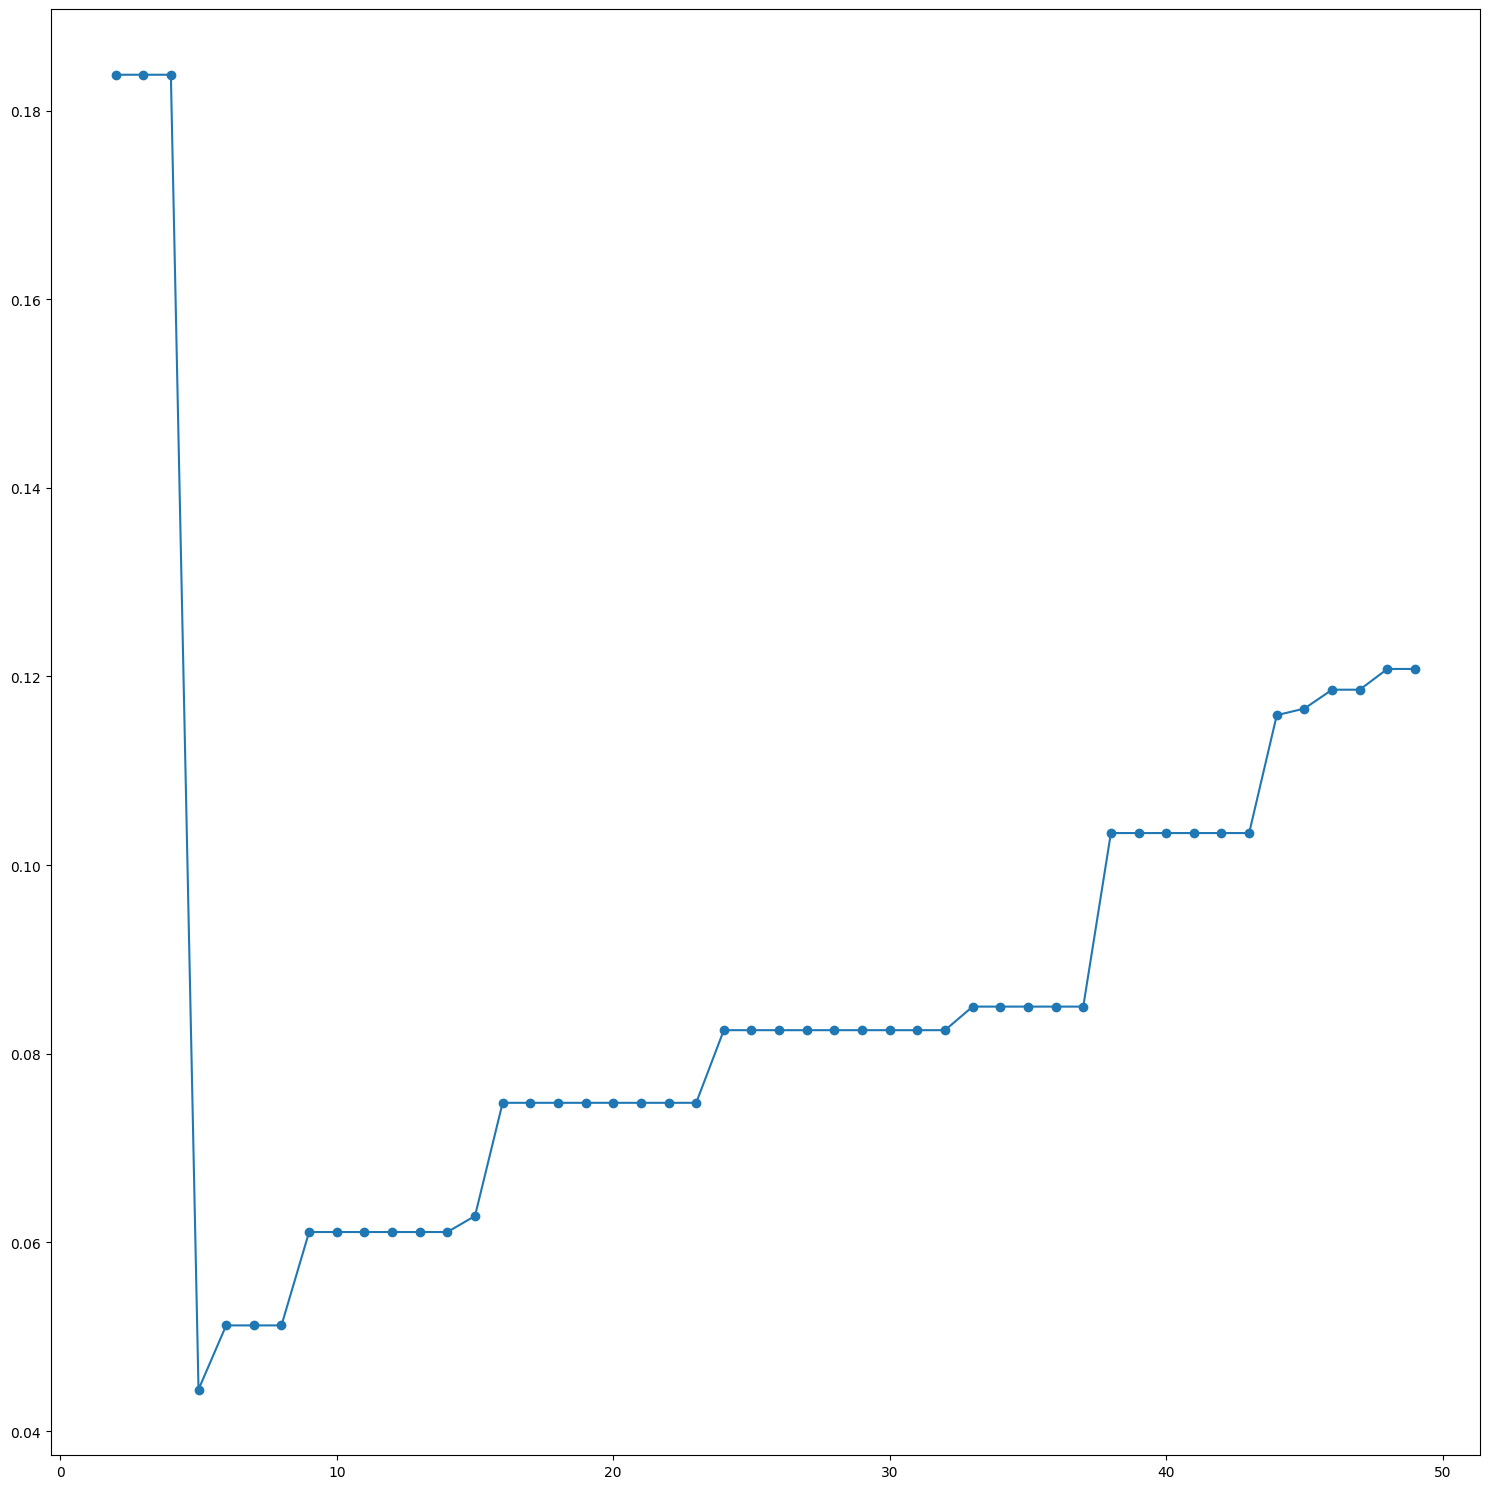

In [25]:
Dunn_index = dict()
bound = 50
for nb_clus in range(2, bound):
    clusters = fcluster(Z, nb_clus, criterion="maxclust")
    clusters = clusters.tolist()
    dict_clusters = {}
    for i in range(1, nb_clus + 1):
        dict_clusters[i] = []
    for i in range(len(clusters)):
        dict_clusters[clusters[i]].append(i)

    list_clusters = [0] * len(alphabets)
    for i in dict_clusters:
        for j in dict_clusters[i]:
            list_clusters[j] = "C" + str(i)
    
    DI = Dunn(dict_dist, dict_clusters)
    Dunn_index[nb_clus] = np.round(DI,4)

Dunn_index_list = list(Dunn_index.values())

Dunn_index = {k: v for k, v in sorted(Dunn_index.items(), key=lambda item: item[1], reverse=True)}
print(Dunn_index)

fig, axes = plt.subplots(1, 1)
plt.scatter(range(2, bound), Dunn_index_list)
axes.plot(range(2, bound), Dunn_index_list)
plt.rcParams["figure.figsize"] = [15, 5]
plt.rcParams["figure.autolayout"] = True
plt.show()

### Davies-Bouldin index
- lower = better

In [26]:
print("The Davies-Bouldin index is", Davies_Bouldin(dict_dist, dict_clusters))

The Davies-Bouldin index is inf


C:\Users\meyerp\Documents\Glyph\worldwide\code github\glyph-worldwide\src\clustering_quality_indices.py:95: RuntimeWarning: divide by zero encountered in double_scalars
  ratio = (sigmas[i] + sigmas[j]) / centroid_dist


{8: 0.291, 9: 0.3134, 6: 0.4145, 5: 0.5112, 4: 0.5167, 19: 0.6984, 18: 0.7575, 17: 0.8171, 12: 0.8243, 16: 0.8344, 15: 0.8522, 13: 1.1271, 14: 1.1706, 11: 1.5079, 10: 1.6356, 7: 1.7119, 2: 3.0492, 3: 8.0885}


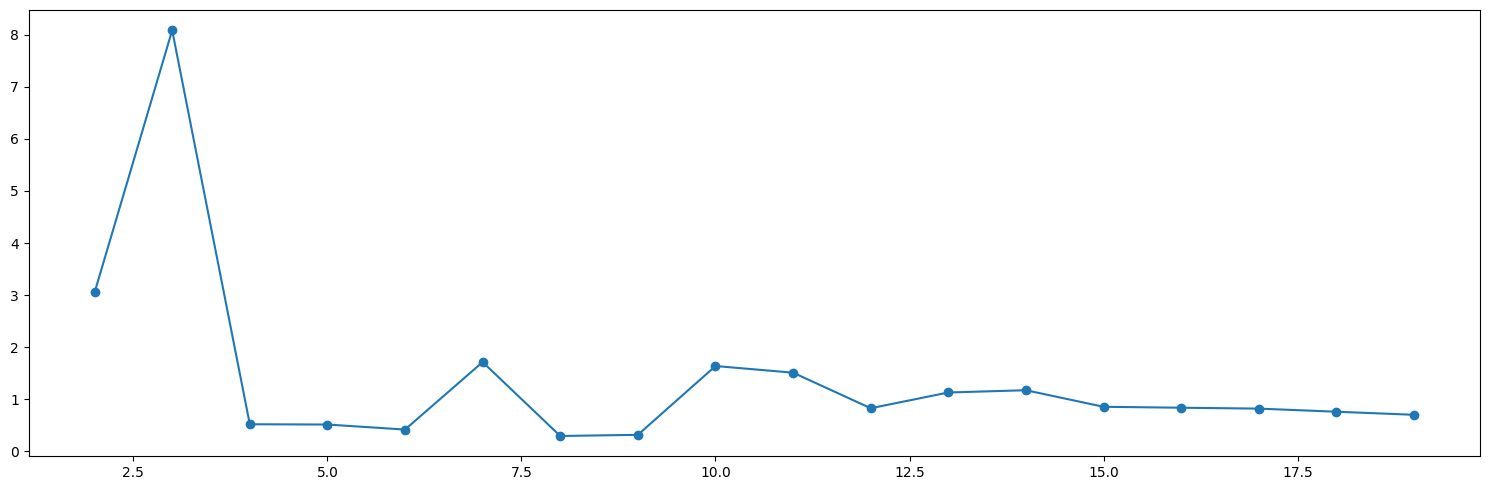

In [27]:
DB_index = dict()
bound = 20
for nb_clus in range(2, bound):
    clusters = fcluster(Z, nb_clus, criterion="maxclust")
    clusters = clusters.tolist()
    dict_clusters = {}
    for i in range(1, nb_clus + 1):
        dict_clusters[i] = []
    for i in range(len(clusters)):
        dict_clusters[clusters[i]].append(i)

    list_clusters = [0] * len(alphabets)
    for i in dict_clusters:
        for j in dict_clusters[i]:
            list_clusters[j] = "C" + str(i)
    
    DBI = Davies_Bouldin(dict_dist, dict_clusters)
    DB_index[nb_clus] = np.round(DBI,4)

DB_index_list = list(DB_index.values())

DB_index = {k: v for k, v in sorted(DB_index.items(), key=lambda item: item[1], reverse=False)}
print(DB_index)

fig, axes = plt.subplots(1, 1)
plt.scatter(range(2, bound), DB_index_list)
axes.plot(range(2, bound), DB_index_list)
plt.rcParams["figure.figsize"] = [15, 5]
plt.rcParams["figure.autolayout"] = True
plt.show()

## Visualisation of the clustering
We now perform a two-dimensional scaling analysis of the scripts to visualize the clustering.

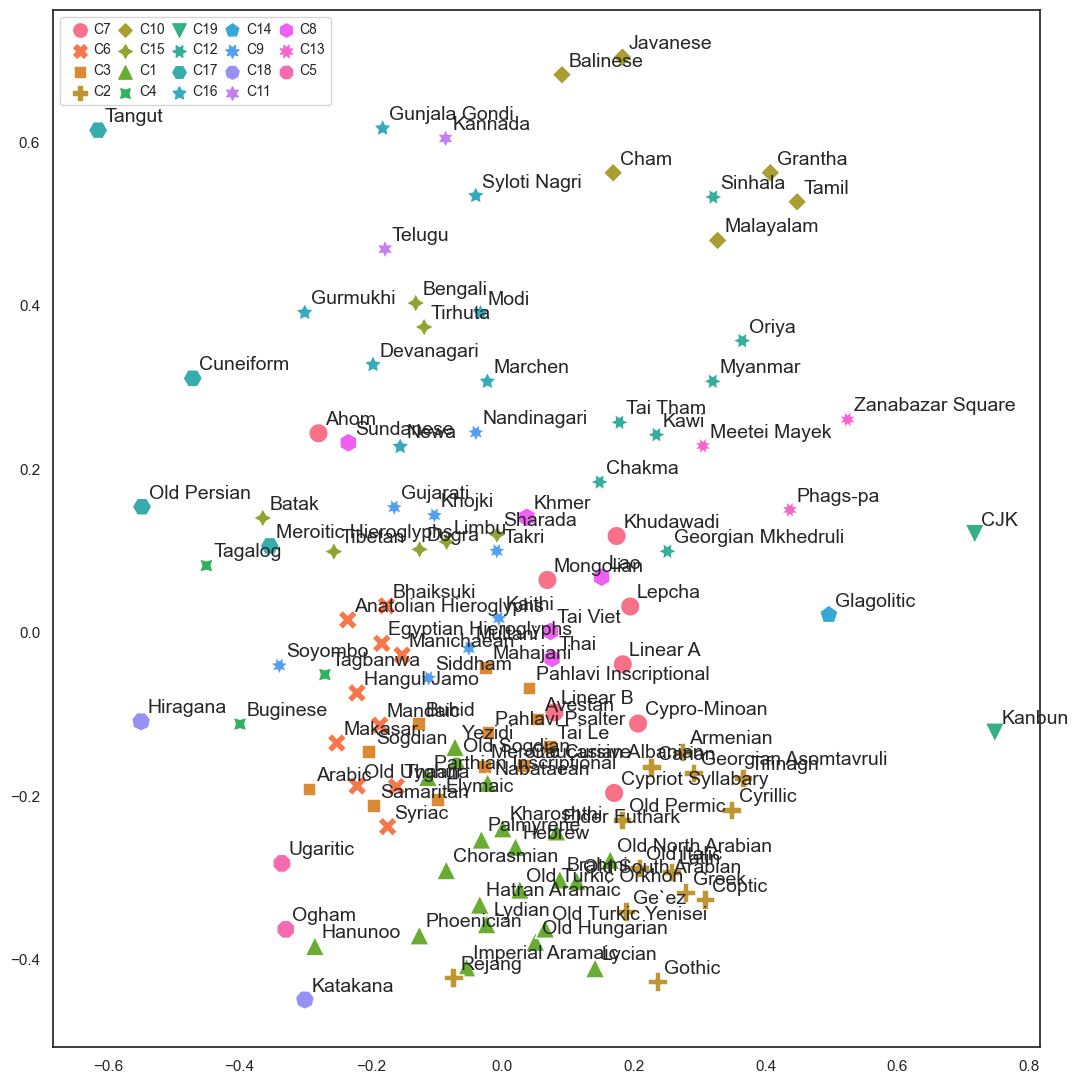

In [28]:
mat_dist = np.zeros((len(alphabets), len(alphabets)))
for i in range(len(alphabets)):
    for j in range(len(alphabets)):
        if i != j:
            mat_dist[i][j] = dict_dist[tuple(sorted((i, j)))]

mds = MDS(
    dissimilarity="precomputed",
    random_state=0,
    n_components=2,
    metric=True,
    normalized_stress=False,
)
mat_dist_MDS_2 = mds.fit_transform(mat_dist)

mat_dist_MDS_2_df = pd.DataFrame(
    data={
        "axis 1": mat_dist_MDS_2[:, 0],
        "axis 2": mat_dist_MDS_2[:, 1],
        "alphabets": alphabets_short,
        "Clusters": list_clusters,
    }
)

sns.set(rc={"figure.figsize": (11, 11)}, font_scale=1.6)
sns.set_theme(style="white")

s = sns.scatterplot(
    x="axis 1",
    y="axis 2",
    data=mat_dist_MDS_2_df,
    hue="Clusters",
    s=200,
    style="Clusters",
    #hue_order=orders,
    #palette=palette,
)
s.legend(
    loc="upper left",
    #bbox_to_anchor=(-0.015, 1.07),
    ncol=5,
    columnspacing=0.001,
    fontsize=10,
    handletextpad=0,
    markerscale=1.6,
)
s.set_ylabel("")
s.set_xlabel("")

for i in range(0, len(mat_dist_MDS_2)):
    script = alphabets_short[i]
    plt.text(
        mat_dist_MDS_2_df["axis 1"][i]+0.01,
        mat_dist_MDS_2_df["axis 2"][i]+0.01,
        f"{script}",
        fontsize=14,
    )

# to save
plt.rcParams["savefig.dpi"] = 300
# plt.savefig("export.png", dpi=300, bbox_inches="tight")

plt.show()

## Cluster medoids
We compute the medoid of each cluster.

In [ ]:
def medoid(C):
    """Exports the medoid of a cluster."""
    list_temp = []
    for i in C:
        temp = 0
        for j in C:
            if i != j:
                temp += dict_dist[tuple(sorted((i, j)))]
        list_temp.append(temp)
    return C[np.argmin(list_temp)]


def diameter(C):
    """Computes the diameter of a cluster."""
    if len(C) == 1:
        return 0
    temp = []
    for i in range(len(C) - 1):
        for j in range(i + 1, len(C)):
            temp.append(dict_dist[(C[i], C[j])])
    return max(temp)


def dist_mean(C):
    """Computes the mean distance in a cluster."""
    if len(C) == 1:
        return 0
    temp = []
    for i in range(len(C) - 1):
        for j in range(i + 1, len(C)):
            temp.append(dict_dist[(C[i], C[j])])
    return np.mean(temp)


list_size = []
list_medoid = []
list_diameter = []
list_mean_dist = []
list_cluster_num = []
for key in dict_clusters:
    list_cluster_num.append("C" + str(key))
    list_size.append(len(dict_clusters[key]))
    list_medoid.append(alphabets_short[medoid(dict_clusters[key])])
    list_diameter.append(diameter(dict_clusters[key]))
    list_mean_dist.append(dist_mean(dict_clusters[key]))

df = pd.DataFrame(
    {
        "Cluster": list_cluster_num,
        "Size": list_size,
        "Medoid": list_medoid,
        "Diameter": list_diameter,
        "Mean distance": list_mean_dist,
    }
)

pd.set_option("styler.format.precision", 2)
display(df.style.set_caption("Styler precision"))

# Bonus: three-dimensional scaling analysis of all the writing systems

We perform here a three-dimensional scaling analysis of all the scripts.
- This is additional and not present in the paper since three-dimensional plots are not well represented with screenshots. This visualization is interactive and visible by running the notebook.

In [ ]:
mat_dist = np.zeros((len(alphabets), len(alphabets)))
for i in range(len(alphabets)):
    for j in range(len(alphabets)):
        if i != j:
            mat_dist[i][j] = dict_dist[tuple(sorted((i, j)))]

mds = MDS(
    dissimilarity="precomputed",
    random_state=0,
    n_components=3,
    normalized_stress=False,
    metric=True,
)
mat_dist_MDS_3 = mds.fit_transform(mat_dist)

mat_dist_MDS_3_df = pd.DataFrame(
    data={
        "axis 1": mat_dist_MDS_3[:, 0],
        "axis 2": mat_dist_MDS_3[:, 1],
        "axis 3": mat_dist_MDS_3[:, 2],
        "alphabets": alphabets_short,
        "clusters": list_clusters,
    }
)

fig = px.scatter_3d(
    mat_dist_MDS_3_df,
    x="axis 1",
    y="axis 2",
    z="axis 3",
    text="alphabets",
    color="clusters",
)
fig.update_layout(
    autosize=False,
    width=800,
    height=800,
)

fig.show()